# Face-recognition contribution

This notebook uses only real identity images. It resizes them, validates the dataset, creates training-time augmentations for every available class, extracts HOG and RGB-histogram features, trains a simple classifier, and evaluates the face checkpoint. No synthetic identity images are created.

In [1]:
from pathlib import Path
from face_pipeline import patch_dataset, validate_dataset, run_eda, image_paths, show_augmentations, train_and_evaluate

ROOT = Path.cwd()
IMAGE_ROOT = ROOT / "images"
patch_dataset(IMAGE_ROOT)
counts = validate_dataset(IMAGE_ROOT)
counts

Using real images only; no identity images are generated.
Validated 9 readable images; duplicates: 0
Resolution range: (810, 1080) to (1200, 1600)
Class counts: {'Aurele': 3, 'Frank': 3, 'Kenny': 3}


{'Aurele': 3, 'Frank': 3, 'Kenny': 3}

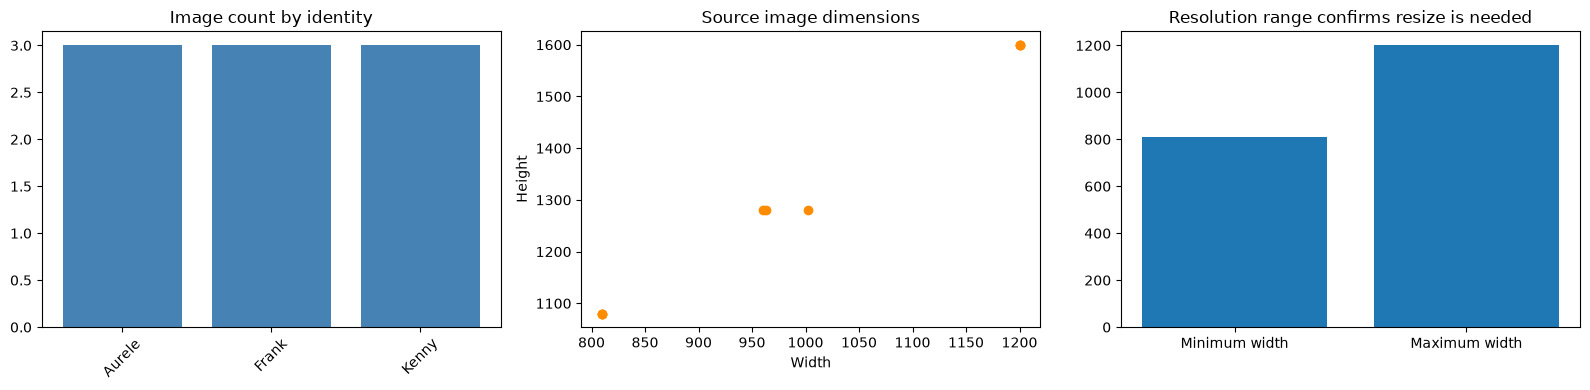

EDA saved: class distribution, source resolutions, and resize justification.


In [2]:
run_eda(IMAGE_ROOT, ROOT / "face_eda.png")
print("EDA saved: class distribution, source resolutions, and resize justification.")

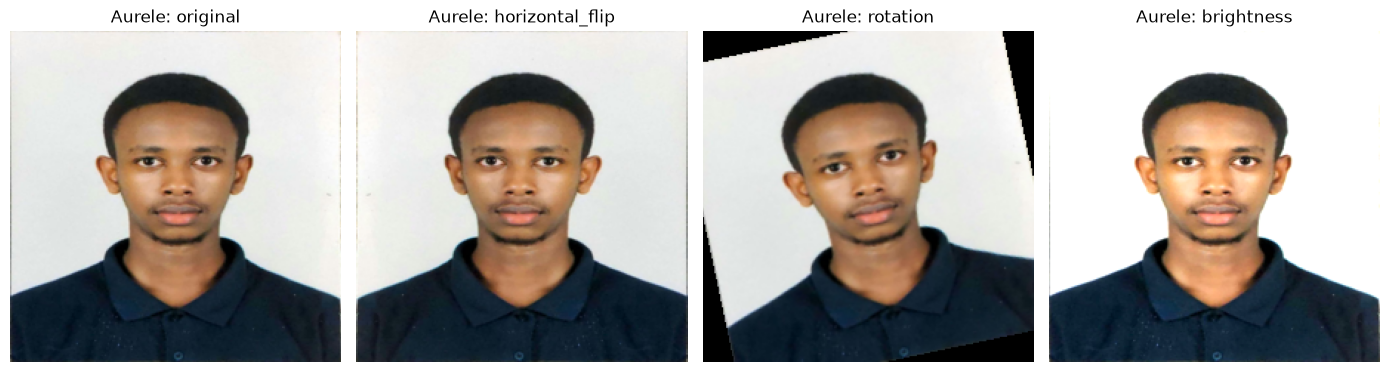

Saved horizontal-flip, rotation, and brightness copies under augmented_images/.


In [3]:
paths = image_paths(IMAGE_ROOT)
show_augmentations(paths, ROOT / "face_augmentations.png", ROOT / "augmented_images")
print("Saved horizontal-flip, rotation, and brightness copies under augmented_images/.")

Validation metrics: {'accuracy': 1.0, 'f1_macro': 1.0, 'log_loss': 0.2903878390789032}
{'accuracy': 1.0, 'f1_macro': 1.0, 'log_loss': 0.2903878390789032}
Created image_features.csv, face_classifier.joblib, and face_confusion_matrix.png.


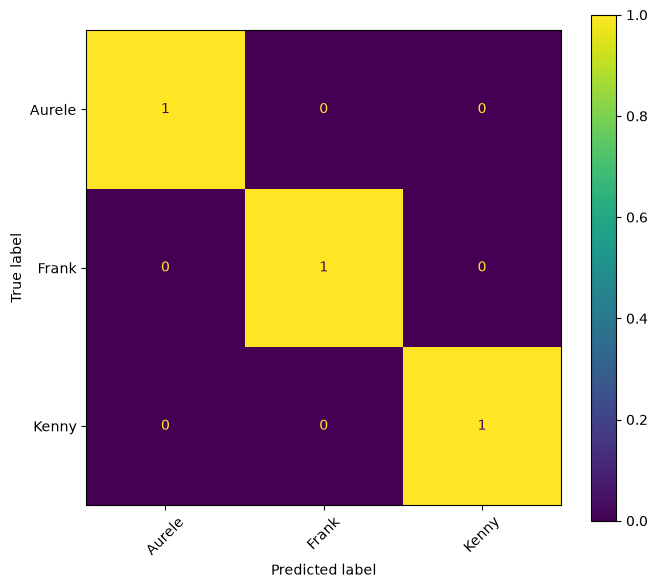

In [4]:
metrics = train_and_evaluate(IMAGE_ROOT, ROOT)
print(metrics)
print("Created image_features.csv, face_classifier.joblib, and face_confusion_matrix.png.")

## CLI demonstration

After adding a real unauthorized person's image folder, run `python face_auth_cli.py images\\Unauthorized\\neutral.jpeg` to test denial. Until then, the face dataset intentionally contains only the real available identities. The CLI authorizes only Aurele, Frank, or Kenny and denies every other predicted label.